# 02 · Stockout early-warning + restock plan

**Business problem.** `monthly_stock` already contains a `stockout_risk_score`, but it is only known *after* the month closes.
We want to (a) **warn one month ahead** which branch × category pairs will be in the high-risk zone (score > 0.70) and
(b) turn the demand forecast from notebook 01 into a concrete **transfer plan**: how many units, from which warehouse, at what cost, in what priority.

**Two parts**
1. **ML model** – classifier: *"will this branch × category have risk > 0.70 next month?"* (features: stock level, months of cover, recent sales, past risk scores, seasonality). Evaluated on future months against a *persistence* baseline ("same as this month").
2. **Rule-based planner** (`cottonil/restock.py`) – transparent policy: target stock = demand over *N* weeks (+ safety = P90), order the gap, pick the cheapest warehouse that has stock. It is a rule rather than a model on purpose: store managers can read and challenge it, and the app lets you change its parameters live.

Requires notebook 01 to have been run (`forecast_latest`).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


In [2]:
from cottonil import restock as R
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve

HIGH = 0.70                       # 'high risk' definition used by the business (see executive dashboard)
ms = load_table("monthly_stock")
lines = load_sales_lines()
last_date = lines.order_date.max()
print("stock rows:", f"{len(ms):,}", "| locations:", ms.stock_location_id.nunique(), "| months:", ms.year_month.nunique())
ms.groupby("stock_location_type").stockout_risk_score.describe().round(3)

stock rows: 142,784 | locations: 92 | months: 97


,count,mean,std,min,25%,50%,75%,max
stock_location_type,,,,,,,,
Branch,124160.0,0.298,0.177,0.000,0.159,0.273,0.414,0.958
Warehouse,18624.0,0.299,0.177,0.001,0.158,0.273,0.415,0.968


## 1 · Build the branch × category × month table

In [3]:
lines["ym"] = lines.order_date.dt.to_period("M").astype(str)
sold = lines.groupby(["branch_id", "category", "ym"], observed=True).quantity.sum().rename("sold").reset_index()
sold["branch_id"] = sold["branch_id"].astype(str); sold["category"] = sold["category"].astype(str)

b = ms[ms.stock_location_type == "Branch"].rename(columns={"stock_location_id": "branch_id", "product_category": "category", "year_month": "ym"})
df = b.merge(sold, on=["branch_id", "category", "ym"], how="left")
df["sold"] = df["sold"].fillna(0)
# the last month is only partly observed -> scale up so it is comparable with full months
last_ym = str(last_date.to_period("M")); frac = last_date.day / last_date.days_in_month
if frac < 0.95:
    df.loc[df.ym == last_ym, "sold"] = df.loc[df.ym == last_ym, "sold"] / frac
    print(f"last month ({last_ym}) is {frac:.0%} observed -> sales scaled x{1 / frac:.2f}")
df = df.sort_values(["branch_id", "category", "ym"]).reset_index(drop=True)
df["mi"] = df.ym.str[:4].astype(int) * 12 + df.ym.str[5:7].astype(int)
g = df.groupby(["branch_id", "category"], sort=False)
df["risk_lag1"] = g.stockout_risk_score.shift(1); df["risk_lag2"] = g.stockout_risk_score.shift(2)
df["risk_mean3"] = df[["stockout_risk_score", "risk_lag1", "risk_lag2"]].mean(axis=1)
df["sold_lag1"] = g.sold.shift(1)
df["sold_m3"] = g.sold.transform(lambda s: s.rolling(3, min_periods=1).mean())
df["cover_months"] = df.closing_units / (df.sold_m3 + 0.5)
df["stock_change"] = df.closing_units / (g.closing_units.shift(1) + 1)
df["month"] = df.ym.str[5:7].astype(int)
df["branch_code"] = pd.Categorical(df.branch_id).codes.astype(int); df["category_code"] = pd.Categorical(df.category).codes.astype(int)
df["risk_next"] = g.stockout_risk_score.shift(-1)
df["y"] = (df.risk_next > HIGH).astype(float).where(df.risk_next.notna())
FEATS = ["closing_units", "closing_stock_value_EGP", "stockout_risk_score", "risk_lag1", "risk_lag2", "risk_mean3", "sold", "sold_lag1",
         "sold_m3", "cover_months", "stock_change", "month", "branch_code", "category_code"]
lab = df[df.y.notna()].copy()
print(f"{len(lab):,} labelled rows | base rate of 'high risk next month' = {lab.y.mean():.1%}")

last month (2026-10) is 58% observed -> sales scaled x1.72


122,880 labelled rows | base rate of 'high risk next month' = 2.2%


## 2 · Time-based split
Train on the past, validate on the next 6 months (to pick the alert threshold), test on the **last 10 labelled months**.

In [4]:
mis = np.sort(lab.mi.unique())
test_mis, val_mis = mis[-10:], mis[-16:-10]
tr, va, te = lab[lab.mi < val_mis[0]], lab[lab.mi.isin(val_mis)], lab[lab.mi.isin(test_mis)]
print(f"train {len(tr):,} | validation {len(va):,} | test {len(te):,}")
clf = HistGradientBoostingClassifier(learning_rate=0.06, max_iter=300, max_leaf_nodes=24, min_samples_leaf=60, l2_regularization=1.0,
                                     categorical_features=["branch_code", "category_code"], early_stopping=True, validation_fraction=0.15,
                                     n_iter_no_change=20, random_state=42)
clf.fit(tr[FEATS], tr.y)
print("trees used:", clf.n_iter_)

train 102,400 | validation 7,680 | test 12,800


trees used: 26


## 3 · Evaluate vs the "persistence" baseline
*Persistence* = "next month's risk will be this month's risk". If the model cannot beat that, an ML model adds nothing.
We report ROC-AUC, PR-AUC (better for rare events) and, at a **threshold chosen on validation only**, precision/recall on test.

In [5]:
p_va, p_te = clf.predict_proba(va[FEATS])[:, 1], clf.predict_proba(te[FEATS])[:, 1]
prec, rec, thr = precision_recall_curve(va.y, p_va)
f1 = 2 * prec * rec / (prec + rec + 1e-9); THRESH = float(thr[np.argmax(f1[:-1])])
def report(y, p, name, t):
    pred = p >= t
    return {"model": name, "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, np.clip(p, 0, 1)),
            "precision@thr": (y[pred].mean() if pred.any() else np.nan), "recall@thr": (pred[y == 1].mean() if (y == 1).any() else np.nan), "alerts": int(pred.sum())}
persist = te.stockout_risk_score.values
thr_persist = HIGH
tab = pd.DataFrame([report(te.y.values, p_te, f"HistGB (thr={THRESH:.2f})", THRESH),
                    report(te.y.values, persist, "persistence (risk_t > 0.70)", thr_persist)]).set_index("model")
print(f"test base rate: {te.y.mean():.1%}")
tab.round(3)

test base rate: 2.2%


,ROC-AUC,PR-AUC,Brier,precision@thr,recall@thr,alerts
model,,,,,,
HistGB (thr=0.03),0.499,0.022,0.022,0.016,0.067,1194
persistence (risk_t > 0.70),0.537,0.026,0.127,0.039,0.039,281


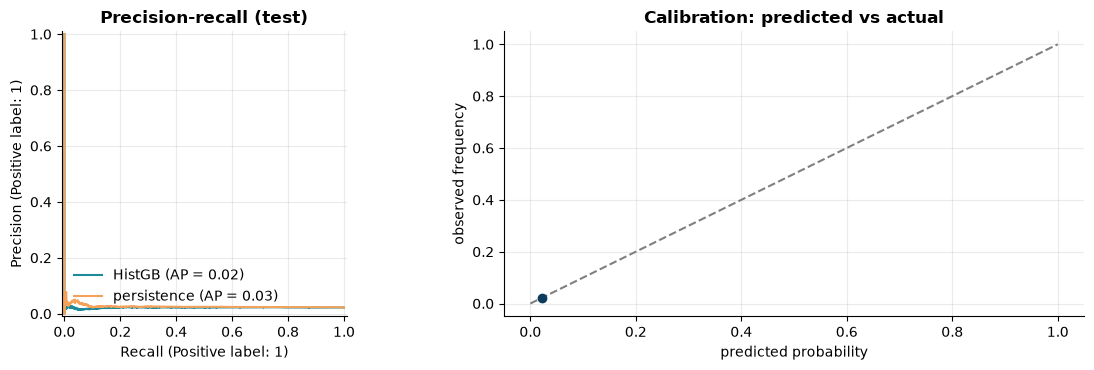

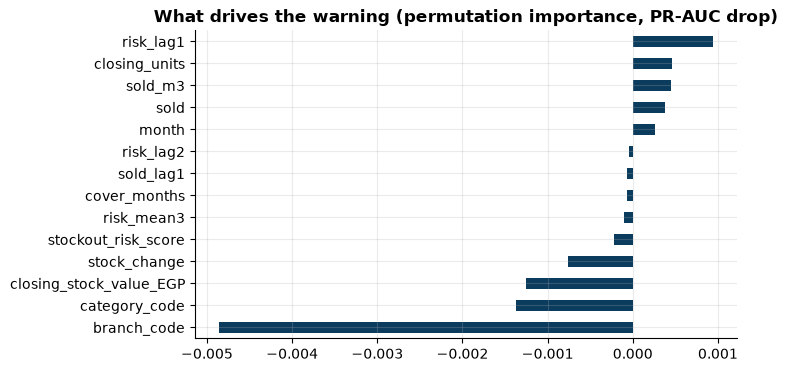

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
from sklearn.metrics import PrecisionRecallDisplay
PrecisionRecallDisplay.from_predictions(te.y, p_te, ax=ax[0], name="HistGB", color=TEAL)
PrecisionRecallDisplay.from_predictions(te.y, persist, ax=ax[0], name="persistence", color=ORANGE); ax[0].set_title("Precision-recall (test)")
bins = pd.cut(p_te, np.linspace(0, 1, 11)); cal = pd.DataFrame({"p": p_te, "y": te.y.values}).groupby(bins, observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
ax[1].plot([0, 1], [0, 1], "--", color="grey"); ax[1].plot(cal.p, cal.y, "o-", color=NAVY); ax[1].set_title("Calibration: predicted vs actual"); ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("observed frequency")
plt.tight_layout(); plt.show()
imp = pd.Series(__import__("sklearn.inspection", fromlist=["x"]).permutation_importance(clf, te[FEATS].sample(min(8000, len(te)), random_state=0), te.y.loc[te[FEATS].sample(min(8000, len(te)), random_state=0).index], n_repeats=3, random_state=0, scoring="average_precision").importances_mean, index=FEATS).sort_values()
imp.plot.barh(color=NAVY, figsize=(7, 4), title="What drives the warning (permutation importance, PR-AUC drop)"); plt.show()

## 4 · Refit on all labelled data, score the latest month

In [7]:
final = HistGradientBoostingClassifier(**{**clf.get_params(), "max_iter": max(clf.n_iter_, 30), "early_stopping": False}).fit(lab[FEATS], lab.y)
latest_mi = df.mi.max()
cur = df[df.mi == latest_mi].copy()
cur["p_high_risk_next"] = final.predict_proba(cur[FEATS])[:, 1]
cur["alert"] = cur.p_high_risk_next >= THRESH
print(f"latest month {cur.ym.iloc[0]}: {len(cur)} branch x category pairs | alerts: {cur.alert.sum()} ({cur.alert.mean():.1%}) | already high risk now: {(cur.stockout_risk_score > HIGH).sum()}")
cfg.save_model("stockout_risk", {"model": final, "features": FEATS, "threshold": THRESH, "high_risk_cut": HIGH, "data_source": SOURCE,
                                 "branch_cats": (sorted(df.branch_id.unique()), sorted(df.category.unique()))})
cur[["branch_id", "category", "closing_units", "stockout_risk_score", "p_high_risk_next", "alert", "cover_months"]].sort_values("p_high_risk_next", ascending=False).head(8).round(3)

latest month 2026-10: 1280 branch x category pairs | alerts: 104 (8.1%) | already high risk now: 29


,branch_id,category,closing_units,stockout_risk_score,p_high_risk_next,alert,cover_months
36083,BR024,Girls underwear,360,0.079,0.056,True,32.132
9505,BR007,Boys pajamas,474,0.226,0.054,True,19.509
85747,BR056,Girls underwear,171,0.343,0.054,True,64.573
98357,BR064,Kids underwear,312,0.485,0.049,True,5.428
30457,BR020,Men underwear,334,0.336,0.049,True,16.700
9699,BR007,Girls underwear,300,0.360,0.044,True,44.505
33658,BR022,Socks,74,0.237,0.044,True,0.484
103789,BR067,Women pajamas,361,0.779,0.042,True,22.002


## 5 · Restock plan (forecast + stock + warehouses + transport cost)
Uses `cottonil.restock.build_restock_plan`. Parameters: **cover weeks** (how many weeks of demand a branch should hold) and
**safety** (0 = plan on the mean forecast, 1 = plan on the P90 forecast).

In [8]:
fl = cfg.load_serving("forecast_latest")
fc4 = R.aggregate_forecast(fl)
wh = load_table("warehouses")
ms_last = ms[ms.year_month == ms.year_month.max()]
wh_stock = (ms_last[ms_last.stock_location_type == "Warehouse"].rename(columns={"stock_location_id": "warehouse_id", "product_category": "category"})
            .merge(wh[["warehouse_id", "warehouse_kind"]], on="warehouse_id"))
wh_stock = wh_stock[wh_stock.warehouse_kind.isin(R.DC_KINDS)][["warehouse_id", "category", "closing_units"]]
tcost = R.transfer_cost_table(load_table("inventory_transfers"))
recent = lines[lines.order_date > last_date - pd.Timedelta(days=365)]
price = (recent.groupby("category", observed=True).apply(lambda x: x.net_line_EGP.sum() / x.quantity.sum()).rename("avg_price").reset_index())
price["category"] = price["category"].astype(str)
stock_now = cur[["branch_id", "category", "closing_units", "stockout_risk_score", "p_high_risk_next"]].copy()

plan = R.build_restock_plan(stock_now, fc4, wh_stock, tcost, price, cover_weeks=4.0, safety=1.0)
print(plan.action.value_counts().to_string())
print(f"\nunits to move: {plan.ship_qty.sum():,} | est. transport cost: EGP {plan.est_transfer_cost_egp.sum():,.0f} | demand at risk without action: EGP {plan.shortfall_value_egp.sum():,.0f}")
plan[["priority_rank", "branch_id", "category", "closing_units", "weekly_mean", "weeks_of_cover", "p_high_risk_next", "order_qty", "source_warehouse", "ship_qty", "est_transfer_cost_egp", "action"]].head(10).round(2)

action
OVERSTOCK    1009
OK            145
RESTOCK       108
URGENT         18

units to move: 8,012 | est. transport cost: EGP 38,215 | demand at risk without action: EGP 1,232,098


,priority_rank,branch_id,category,closing_units,weekly_mean,weeks_of_cover,p_high_risk_next,order_qty,source_warehouse,ship_qty,est_transfer_cost_egp,action
0,1,BR006,Men boxers,14,19.33,0.7,0.02,107,WH02,107,280.0,URGENT
1,2,BR037,Men boxers,16,18.66,0.9,0.02,101,WH02,101,280.0,URGENT
2,3,BR068,Men tops,12,21.16,0.6,0.02,120,WH04,120,280.0,URGENT
3,4,BR035,Men tops,19,22.01,0.9,0.02,118,WH03,118,280.0,URGENT
4,5,BR036,Men boxers,19,16.45,1.2,0.03,84,WH07,84,280.0,URGENT
5,6,BR036,Men tops,12,18.33,0.7,0.02,103,WH07,103,280.0,URGENT
6,7,BR034,Men boxers,34,19.07,1.8,0.03,86,WH12,86,280.0,RESTOCK
7,8,BR044,Men boxers,39,19.27,2.0,0.02,82,WH01,82,280.0,RESTOCK
8,9,BR054,Men boxers,47,20.83,2.3,0.02,84,WH01,84,365.0,RESTOCK
9,10,BR005,Men tops,35,21.51,1.6,0.02,100,WH01,100,280.0,RESTOCK


In [9]:
# sensitivity: how does the policy trade stock vs. service?
rows = []
for cw in (2, 3, 4, 6):
    for sf in (0.0, 1.0):
        p = R.build_restock_plan(stock_now, fc4, wh_stock, tcost, price, cover_weeks=cw, safety=sf)
        rows.append({"cover_weeks": cw, "safety (0=mean,1=P90)": sf, "branch-cats to restock": int((p.order_qty > 0).sum()), "units to ship": int(p.ship_qty.sum()),
                     "transport cost EGP": round(p.est_transfer_cost_egp.sum())})
pd.DataFrame(rows)

,cover_weeks,"safety (0=mean,1=P90)",branch-cats to restock,units to ship,transport cost EGP
0,2,0.0,29,644,8460
1,2,1.0,55,1813,16760
2,3,0.0,53,1663,16030
3,3,1.0,90,4315,27030
4,4,0.0,75,3075,22235
5,4,1.0,126,8012,38215
6,6,0.0,123,7373,37375
7,6,1.0,210,19082,63650


## 6 · Export for the app

In [10]:
cfg.save_serving("stock_latest", stock_now.round(4))
cfg.save_serving("warehouse_stock_latest", wh_stock)
cfg.save_serving("transfer_costs", tcost)
cfg.save_serving("category_price", price.round(2))
cfg.save_serving("restock_plan", plan.round(3))
# history of risk for the chart in the app (network average by month and category)
hist = df.groupby(["ym", "category"]).agg(avg_risk=("stockout_risk_score", "mean"), share_high=("stockout_risk_score", lambda s: (s > HIGH).mean())).reset_index()
cfg.save_serving("risk_history", hist.round(4))
cfg.save_metrics("02_stockout_risk", {"test_base_rate": float(te.y.mean()), "threshold": THRESH, "model": tab.loc[tab.index[0]].round(4).to_dict(),
                                      "persistence_baseline": tab.loc[tab.index[1]].round(4).to_dict(), "n_alerts_latest": int(cur.alert.sum()),
                                      "plan_actions": plan.action.value_counts().to_dict(), "plan_units": int(plan.ship_qty.sum()),
                                      "plan_transport_cost_egp": float(plan.est_transfer_cost_egp.sum()), "latest_month": str(cur.ym.iloc[0])}, DATA_DIR)
print("saved")

saved


## Takeaways
* The classifier is judged against *persistence*; only trust it if PR-AUC clearly beats the baseline on real data.
* The restock plan is a policy on top of the forecast – tune `cover_weeks`/`safety` with the supply team (the app has sliders for this).
* Caveat: stock data is category-level, so plans are per category; SKU-level stock would enable size/colour-level transfers.